# Digits Playground

### Import Libraries

In [31]:
import matplotlib.pyplot as plt
from sklearn import datasets, manifold
import umap

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
import numpy as np

### Load Digits Dataset

In [22]:
digits = datasets.load_digits()
X_digits = digits.data   # The 64D pixel arrays (1797, 64)
y_digits = digits.target # The actual number (0-9) labels

## Testing Algorithms

### Visualize Original Dataset

##### **Grid of Digits:**

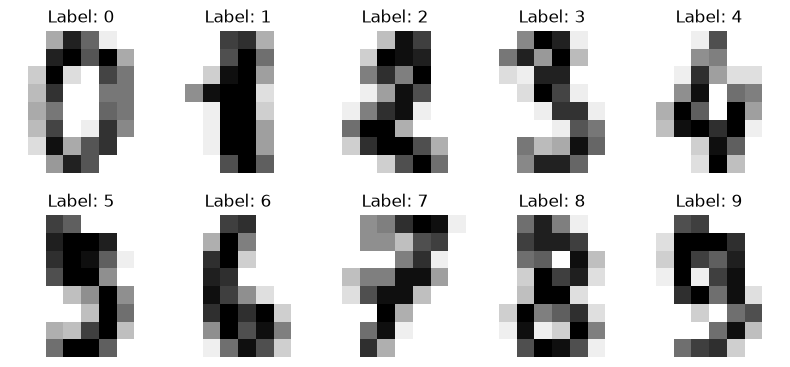

In [30]:
fig, axes = plt.subplots(2, 5, figsize=(8, 4))
axes = axes.ravel() # Flatten the 2x5 grid into a simple list so we can loop through it easily

for i in range(10):
    axes[i].imshow(digits.images[i], cmap=plt.cm.gray_r, interpolation='nearest')
    axes[i].set_title(f"Label: {digits.target[i]}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### Apply Manifold Learning

In [32]:
isomap = manifold.Isomap(n_components=2, n_neighbors=15)
X_isomap = isomap.fit_transform(X_digits)
print(f"Isomap - New shape of X: {X_isomap.shape}")

tsne = manifold.TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_digits)
print(f"TSNE - New shape of X: {X_tsne.shape}")

umap = umap.UMAP(n_components=2, random_state=42)
X_umap = umap.fit_transform(X_digits)
print(f"UMAP - New shape of X: {X_umap.shape}")

Isomap - New shape of X: (1797, 2)
TSNE - New shape of X: (1797, 2)


UMAP - New shape of X: (1797, 2)


### Plot Result

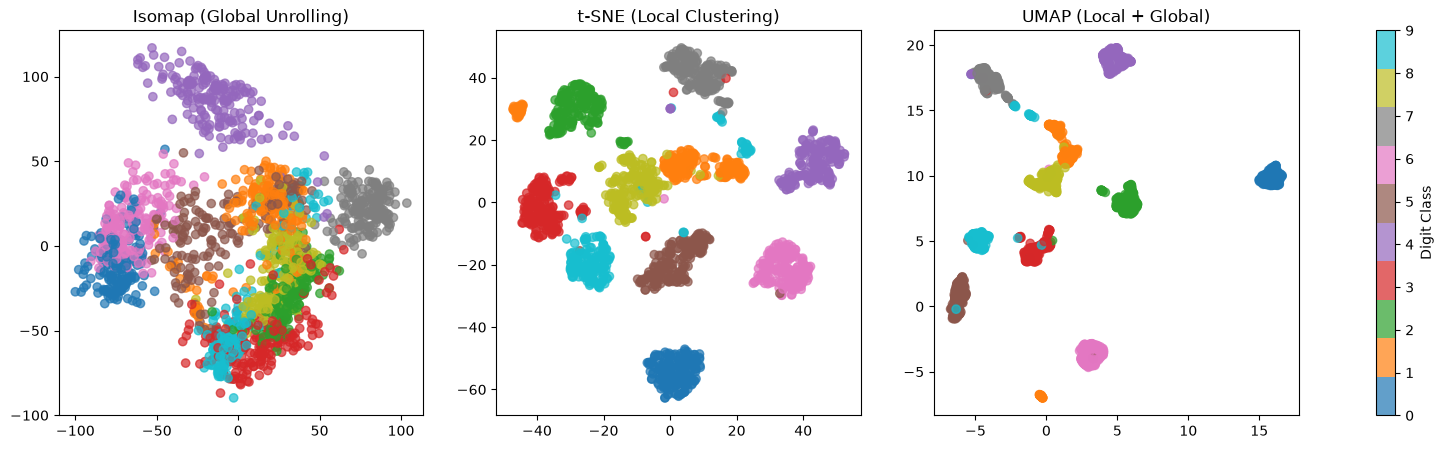

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Plot Isomap
iso = axes[0].scatter(X_isomap[:, 0], X_isomap[:, 1], c=y_digits, cmap='tab10', alpha=0.7)
axes[0].set_title("Isomap (Global Unrolling)")

# Plot t-SNE
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_digits, cmap='tab10', alpha=0.7)
axes[1].set_title("t-SNE (Local Clustering)")

# Plot UMAP
axes[2].scatter(X_umap[:, 0], X_umap[:, 1], c=y_digits, cmap='tab10', alpha=0.7)
axes[2].set_title("UMAP (Local + Global)")

fig.colorbar(iso, ax=axes, ticks=range(10), label='Digit Class')
plt.show()

## Training + Testing a NN

### Splitting Data

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.4, random_state=42 
) # keep 40% for testing

print(f"Training on {len(X_train)} images.")
print(f"Testing on {len(X_test)} images.")

Training on 1078 images.
Testing on 719 images.


### Training

In [38]:
nn = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42) # creating nn
nn.fit(X_train, y_train) # training
print("Training complete!")

Training complete!


### Testing

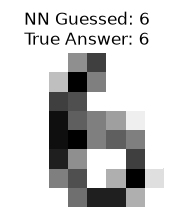

In [41]:
# Grab the very first image in our test pile
test_image = X_test[0]
true_answer = y_test[0]

# Ask the neural network to predict it. 
# (It expects a list of images, so we put our one image in brackets)
prediction = nn.predict([test_image])

# Plot the result!
plt.figure(figsize=(2, 2))
# We have to reshape the 64-number array back into an 8x8 grid to draw it
plt.imshow(test_image.reshape(8, 8), cmap=plt.cm.gray_r)
plt.title(f"NN Guessed: {prediction[0]}\nTrue Answer: {true_answer}")
plt.axis('off')
plt.show()

In [48]:
# 1. Predict all test images
all_predictions = nn.predict(X_test)

# 2. Compare the predictions to the true answers (y_test)
# np.where() looks for every index where the prediction does NOT equal the truth
failed_indices = np.where(all_predictions != y_test)[0]

print(f"The network made {len(failed_indices)} mistakes out of {len(X_test)} tests.")
print(f"The indices of the failed images in X_test are: {failed_indices}")

accuracy = nn.score(X_test, y_test)
print(f"Overall Accuracy: {accuracy * 100}%")
print(f"Overall Accuracy: {100 - len(failed_indices)/len(X_test) * 100}%")

The network made 22 mistakes out of 719 tests.
The indices of the failed images in X_test are: [  5  60  71 133 149 156 204 244 270 314 339 431 450 516 563 572 578 598
 604 607 686 698]
Overall Accuracy: 96.94019471488178%
Overall Accuracy: 96.94019471488178%


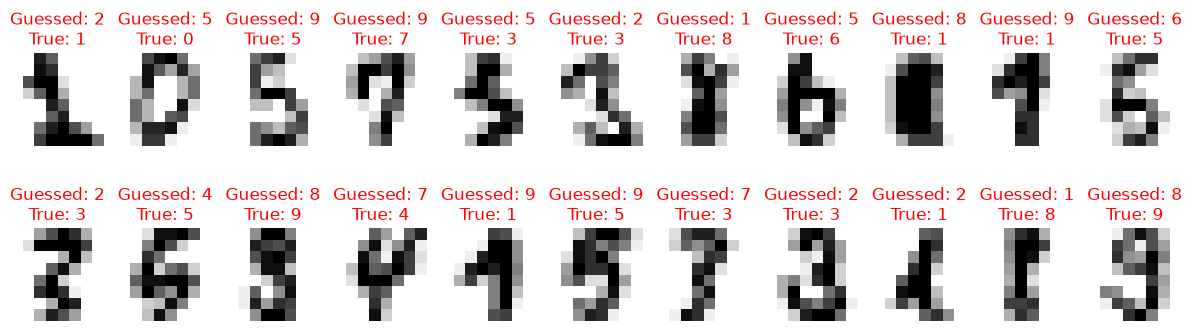

In [55]:
# Create a plot with 4 side-by-side images
fig, axes = plt.subplots(2, 11, figsize=(12, 4))
axes = axes.ravel() 

# Loop through the first 4 failed indices
for i, ax in enumerate(axes):
    if i < len(failed_indices):
        # Grab the specific index where it failed
        idx = failed_indices[i]
        
        # Get the image, the wrong guess, and the true answer
        failed_image = X_test[idx]
        wrong_guess = all_predictions[idx]
        true_answer = y_test[idx]
        
        # Plot it (remembering to reshape back to 8x8)
        ax.imshow(failed_image.reshape(8, 8), cmap=plt.cm.gray_r)
        ax.set_title(f"Guessed: {wrong_guess}\nTrue: {true_answer}", color="red")
        ax.axis('off')

plt.tight_layout()
plt.show()

### tSNE pipeline

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. First, use Isomap to compress 64 dimensions down to just 10
# 2. Then, pass those 10 dimensions to the Neural Network
# We use a pipeline to chain these steps together seamlessly
magic_pipeline = make_pipeline(
    manifold.Isomap(n_components=10, n_neighbors=15), 
    MLPClassifier(hidden_layer_sizes=(50,), max_iter=500, random_state=42)
)

# Train the pipeline! 
# It will automatically reduce the training data, then train the network on the smaller data.
magic_pipeline.fit(X_train, y_train)
predictions = magic_pipeline.predict(X_test)
fails = np.where(predictions != y_test)[0]

print(f"The network made {len(fails)} mistakes out of {len(X_test)} tests.")
print(f"The indices of the failed images in X_test are: {fails}")

accuracy = magic_pipeline.score(X_test, y_test)
print(f"Pipeline Accuracy: {accuracy * 100}%") # same accuracy, which is good! isomap compression deleted noise / did not overcompress -> saves computing power

The network made 22 mistakes out of 719 tests.
The indices of the failed images in X_test are: [ 10  76  97 118 133 159 204 244 249 329 346 418 450 515 516 557 584 604
 607 622 686 708]
Pipeline Accuracy: 96.94019471488178%
